<a href="https://colab.research.google.com/github/Rajput-Arush41/Binary-Classification-using-Logistic-Regression/blob/main/notebook/Churn_Prediction_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Binary Classification using Logistic Regression
## Telco Customer Churn Prediction

**Objective:** Apply Logistic Regression to predict customer churn, demonstrating an end-to-end machine learning workflow: EDA, preprocessing, model building, evaluation, interpretation, and reporting.

**Dataset:** Telco Customer Churn Dataset (IBM sample dataset, widely distributed via Kaggle).
**Target:** `Churn` (Yes/No)


---
## Phase 1: Problem Definition & EDA

**Business problem:** Customer churn (a subscriber leaving the telecom service) directly erodes recurring revenue. Acquiring a new customer typically costs far more than retaining an existing one, so being able to flag customers who are *likely* to churn — and understand *why* — lets the business intervene early (e.g. targeted retention offers) before the customer leaves.

We start by loading the raw data and understanding its structure, feature types, and the balance of the target class.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                              recall_score, f1_score, classification_report,
                              roc_curve, roc_auc_score)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

df = pd.read_csv("../data/Dataset.csv")
df.drop(columns=["customerID"], inplace=True)   # identifier, not predictive
df.shape

(7043, 20)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [ ]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Feature types

- **Numerical features:** `tenure`, `MonthlyCharges`, `TotalCharges`
- **Categorical features:** all remaining columns (gender, contract type, service subscriptions, payment method, etc.)

Note: `TotalCharges` is loaded as an object/string dtype because 11 rows contain a blank string (new customers with `tenure == 0` who have not been billed yet). We convert it to numeric now so EDA on it is meaningful.


In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [c for c in df.columns if c not in numerical_features + ["Churn"]]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Missing values:
 TotalCharges    11
dtype: int64


### Target variable distribution — checking for class imbalance

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


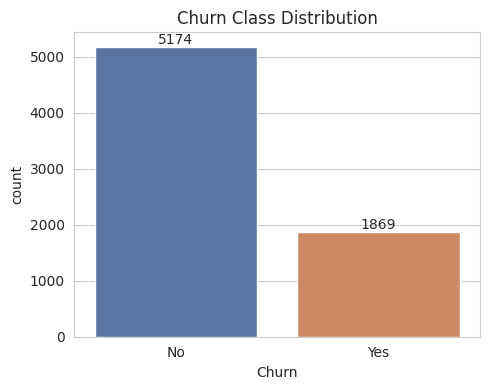

In [ ]:
churn_counts = df["Churn"].value_counts()
churn_pct = df["Churn"].value_counts(normalize=True) * 100
print(churn_counts)
print(churn_pct.round(2))

plt.figure(figsize=(5,4))
ax = sns.countplot(x="Churn", data=df, hue="Churn", palette=["#4C72B0","#DD8452"], legend=False)
plt.title("Churn Class Distribution")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Observation:** The dataset is imbalanced — about 73% of customers did **not** churn vs. 27% who did. This matters for model evaluation (accuracy alone would be misleading) and for training (we address it later using `class_weight='balanced'`).

### Distributions of numerical features

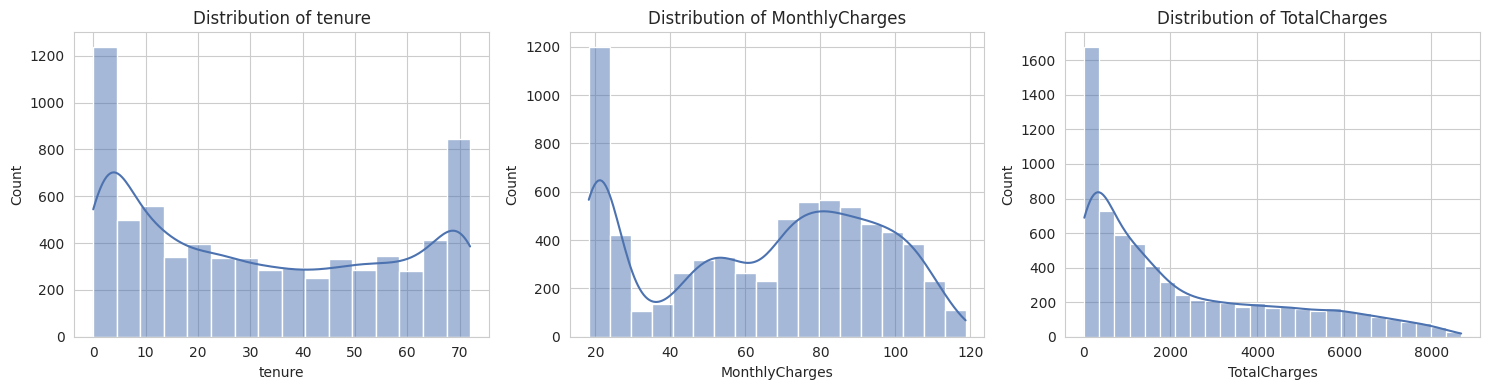

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, col in zip(axes, numerical_features):
    sns.histplot(df[col].dropna(), kde=True, ax=ax, color="#4C72B0")
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

### Boxplots — numerical features vs Churn

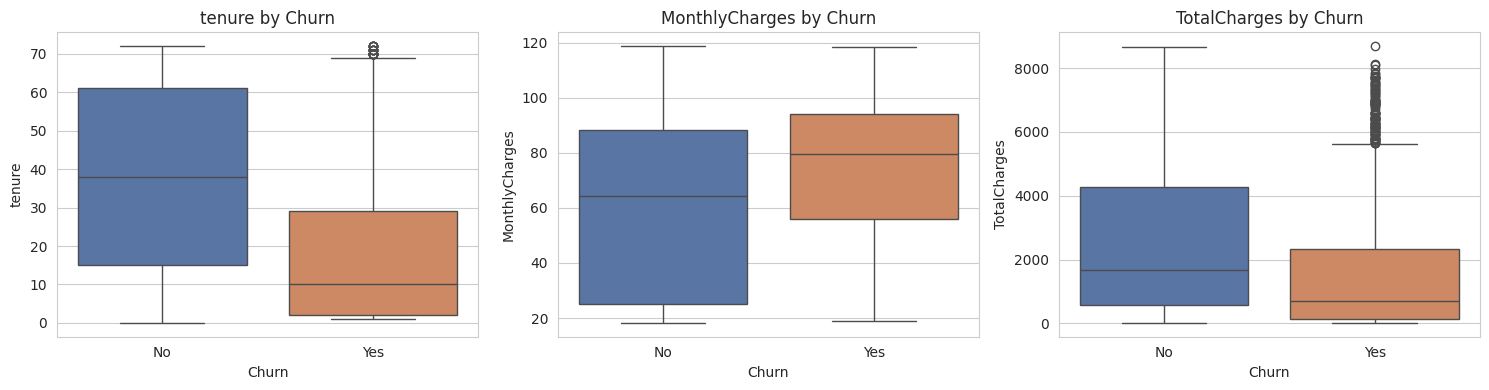

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, col in zip(axes, numerical_features):
    sns.boxplot(x="Churn", y=col, data=df, hue="Churn", palette=["#4C72B0","#DD8452"], legend=False, ax=ax)
    ax.set_title(f"{col} by Churn")
plt.tight_layout()
plt.show()

**Observation:** Customers who churn tend to have **lower tenure** and **higher MonthlyCharges**, and consequently lower cumulative `TotalCharges` (since they leave early). This is an intuitive early signal: newer, higher-paying customers are more likely to leave.

### Correlation heatmap

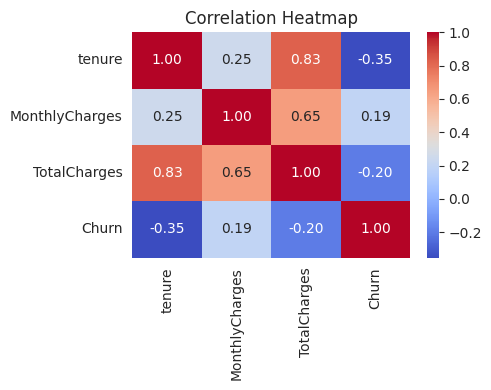

In [ ]:
corr_df = df[numerical_features].copy()
corr_df["Churn"] = (df["Churn"] == "Yes").astype(int)

plt.figure(figsize=(5,4))
sns.heatmap(corr_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Churn rate by key categorical features

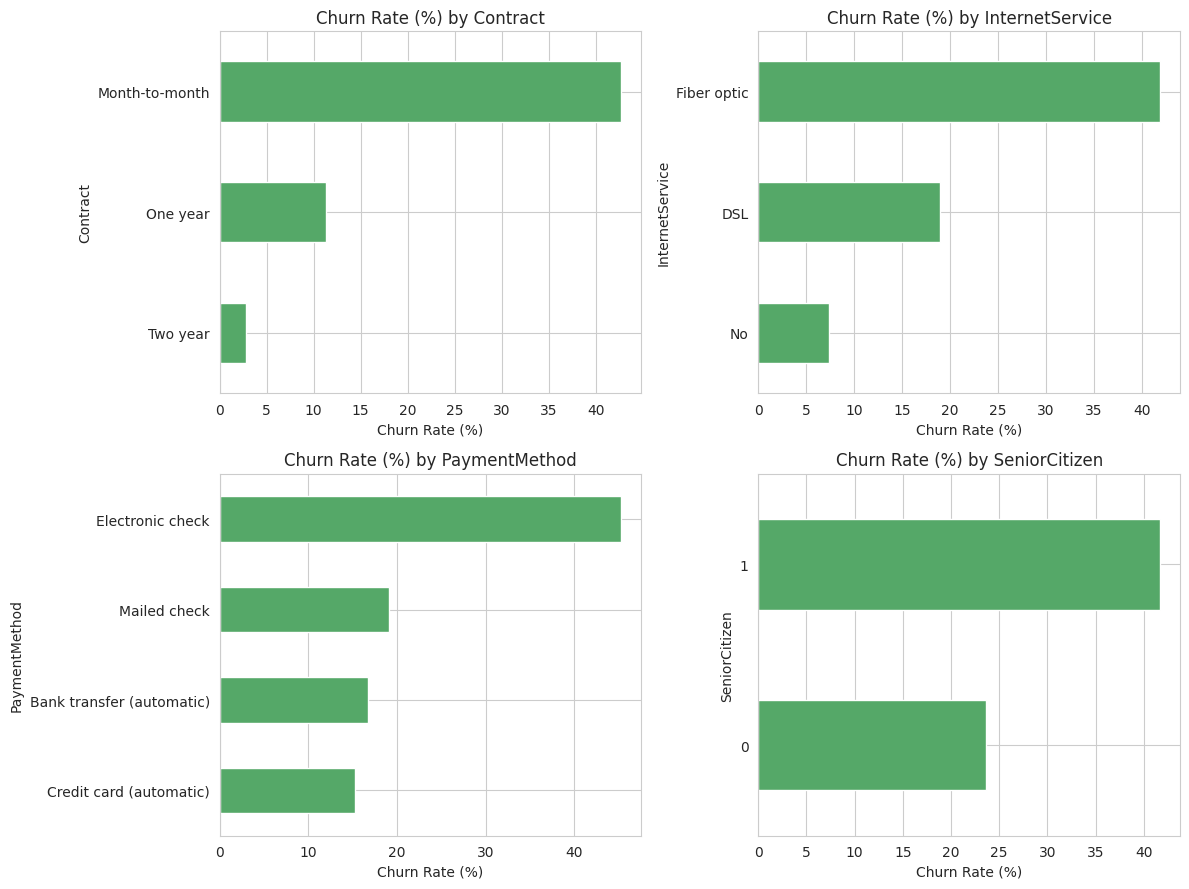

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12,9))
for ax, col in zip(axes.flatten(), ["Contract", "InternetService", "PaymentMethod", "SeniorCitizen"]):
    rate = df.groupby(col)["Churn"].apply(lambda x: (x=="Yes").mean()*100)
    rate.sort_values().plot(kind="barh", ax=ax, color="#55A868")
    ax.set_title(f"Churn Rate (%) by {col}")
    ax.set_xlabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

**Observation:** Month-to-month contracts, Fiber optic internet, and Electronic check payment are associated with markedly higher churn rates — these look like strong predictive signals, which we verify later via the model's coefficients.

---
## Phase 2: Data Preprocessing


### Handle missing values
The only missing values are the 11 blank `TotalCharges` entries, all belonging to customers with `tenure == 0` (i.e., brand-new customers who haven't been billed yet). Since they haven't accumulated any charges, imputing with `0` is the correct, principled choice (not the column mean, which would fabricate billing history that doesn't exist).

In [ ]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
assert df.isnull().sum().sum() == 0
print("Missing values remaining:", df.isnull().sum().sum())

Missing values remaining: 0


### Encode the target and categorical variables

In [ ]:
df["Churn"] = (df["Churn"] == "Yes").astype(int)

# One-Hot Encoding for categorical features (drop_first=True avoids the dummy-variable trap)
df_encoded = pd.get_dummies(df, columns=categorical_features, drop_first=True)

X = df_encoded.drop(columns=["Churn"])
y = df_encoded["Churn"]
print("Feature matrix shape after encoding:", X.shape)

Feature matrix shape after encoding: (7043, 30)


### Train/test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train churn rate: %.2f%%" % (y_train.mean()*100))
print("Test churn rate:  %.2f%%" % (y_test.mean()*100))

Train: (5634, 30)  Test: (1409, 30)
Train churn rate: 26.54%
Test churn rate:  26.54%


We stratify on `y` so both splits preserve the ~73/27 class ratio, keeping evaluation representative.

### Feature scaling

In [ ]:
# Logistic Regression's gradient-based solvers converge faster and coefficients become
# directly comparable in magnitude when numerical features are standardized.
# We fit the scaler on TRAIN only, then apply to test, to avoid data leakage.
scaler = StandardScaler()
X_train[numerical_features] = scaler.fit_transform(X_train[numerical_features])
X_test[numerical_features] = scaler.transform(X_test[numerical_features])
X_train[numerical_features].describe()

,tenure,MonthlyCharges,TotalCharges
count,5.634000e+03,5.634000e+03,5.634000e+03
mean,-1.008935e-17,-2.402527e-16,2.522338e-17
std,1.000089e+00,1.000089e+00,1.000089e+00
min,-1.322329e+00,-1.544028e+00,-1.008922e+00
25%,-9.559779e-01,-9.711977e-01,-8.321009e-01
50%,-1.418632e-01,1.848336e-01,-3.968446e-01
75%,9.164859e-01,8.319124e-01,6.741944e-01
max,1.608483e+00,1.785939e+00,2.801869e+00


---
## Phase 3: Model Implementation

**Hyperparameter choices:**
- `penalty='l2'` — standard ridge-style regularization; keeps all engineered dummy features in the model while shrinking noisy coefficients (appropriate here since we one-hot encoded many categorical levels).
- `C=1.0` — moderate regularization strength (the default); with ~30 features and ~5,600 training rows there's no strong overfitting signal that would justify a smaller C, and no clear underfitting that would justify a much larger one.
- `solver='lbfgs'` — efficient default solver for L2-penalized logistic regression on datasets of this size.
- `class_weight='balanced'` — automatically re-weights the loss function inversely proportional to class frequency, which counteracts the 73/27 imbalance we found in EDA so the model doesn't just learn to always predict "No Churn".


In [ ]:
model = LogisticRegression(
    penalty="l2", C=1.0, solver="lbfgs", class_weight="balanced",
    max_iter=1000, random_state=42
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
print("Model trained.")

Model trained.


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


---
## Phase 4: Model Evaluation


In [ ]:
cm = confusion_matrix(y_test, y_pred)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")

Accuracy:  0.7381
Precision: 0.5043
Recall:    0.7834
F1 Score:  0.6136
ROC-AUC:   0.8417


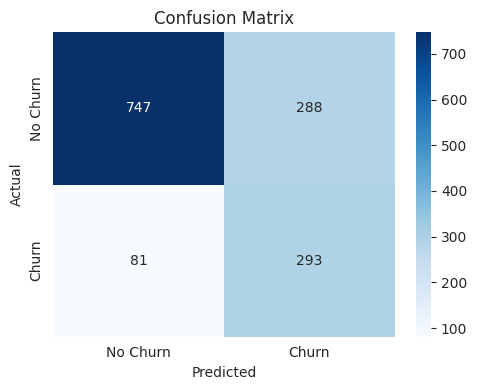

In [ ]:
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Churn","Churn"], yticklabels=["No Churn","Churn"])
plt.ylabel("Actual"); plt.xlabel("Predicted"); plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
print(classification_report(y_test, y_pred, target_names=["No Churn","Churn"]))

              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



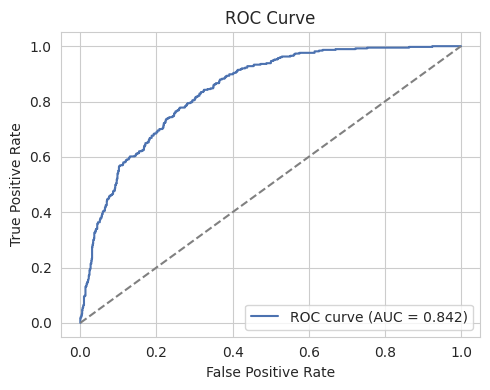

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(5,4))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.3f})", color="#4C72B0")
plt.plot([0,1],[0,1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation of the metrics:**
- **Accuracy (~74%)** alone is a weak summary given the class imbalance — a naive "always predict No Churn" model would already score ~73%.
- **Recall on Churn (~78%)** is high on purpose: `class_weight='balanced'` trades some precision for the ability to catch more actual churners, which fits the business goal (missing a churner who leaves is usually costlier than a false alarm that triggers a retention email).
- **Precision on Churn (~50%)** is moderate — about half of predicted churners are false positives, an acceptable cost if retention outreach is cheap.
- **ROC-AUC (~0.84)** indicates strong overall ability to rank churners above non-churners, independent of the classification threshold.


---
## Phase 5: Interpretation & Insights

Logistic Regression coefficients are directly interpretable: for standardized/dummy features, a positive coefficient means the feature **increases the log-odds of churn**, and a negative coefficient means it **decreases** it.


In [ ]:
coefs = pd.Series(model.coef_[0], index=X.columns).sort_values()
top_positive = coefs.tail(10)[::-1]
top_negative = coefs.head(10)

print("Top drivers that INCREASE churn risk:")
print(top_positive)
print("\nTop drivers that DECREASE churn risk:")
print(top_negative)

Top drivers that INCREASE churn risk:
InternetService_Fiber optic       1.222352
TotalCharges                      0.486541
StreamingMovies_Yes               0.420611
PaymentMethod_Electronic check    0.402478
StreamingTV_Yes                   0.395359
PaperlessBilling_Yes              0.336449
MultipleLines_Yes                 0.324742
SeniorCitizen_1                   0.153869
PaymentMethod_Mailed check        0.052313
DeviceProtection_Yes              0.041152
dtype: float64

Top drivers that DECREASE churn risk:
Contract_Two year                  -1.412536
tenure                             -1.156175
Contract_One year                  -0.715268
MonthlyCharges                     -0.546189
PhoneService_Yes                   -0.348014
OnlineSecurity_Yes                 -0.334946
TechSupport_Yes                    -0.268557
Dependents_Yes                     -0.231225
MultipleLines_No phone service     -0.189277
OnlineBackup_No internet service   -0.183003
dtype: float64


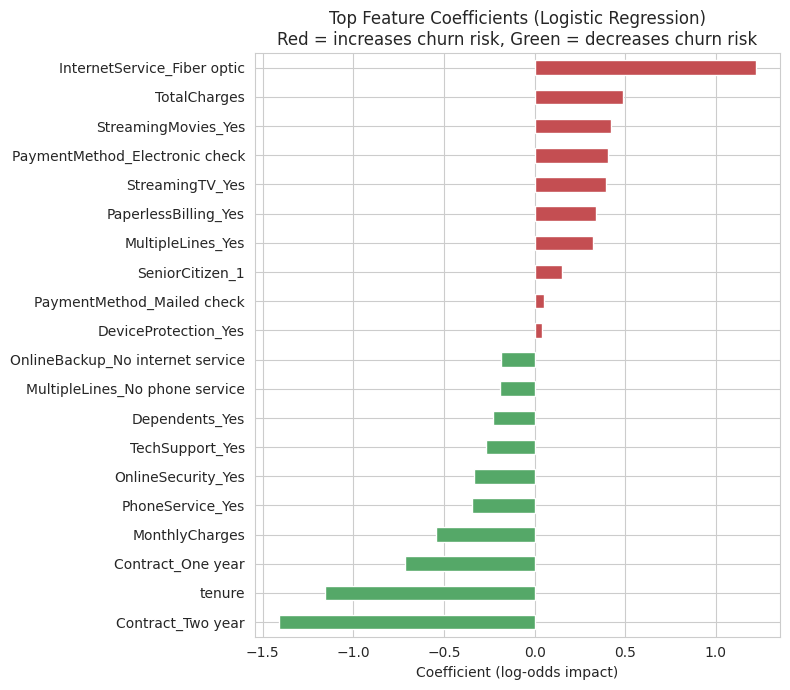

In [ ]:
combined = pd.concat([top_negative, top_positive]).sort_values()
colors = ["#55A868" if v < 0 else "#C44E52" for v in combined]

fig, ax = plt.subplots(figsize=(8,7))
combined.plot(kind="barh", color=colors, ax=ax)
ax.set_title("Top Feature Coefficients (Logistic Regression)\nRed = increases churn risk, Green = decreases churn risk")
ax.set_xlabel("Coefficient (log-odds impact)")
plt.tight_layout()
plt.show()

**Key insights:**
- **Contract type dominates.** `Contract_Two year` and `Contract_One year` are the strongest churn-*reducing* factors — customers locked into longer contracts are far less likely to leave than month-to-month customers (the implicit baseline category).
- **Tenure reduces churn.** The longer a customer has stayed, the less likely they are to leave — consistent with the boxplots in EDA.
- **Fiber optic internet increases churn risk** the most among service features — despite being a premium product, it's associated with higher dissatisfaction or price sensitivity (possibly due to higher cost or service issues).
- **Paperless billing, electronic check payment, and add-on streaming services** are mild churn-increasing factors — possibly correlated with a segment of price-sensitive, digitally-only customers.
- **Security/support add-ons reduce churn.** `OnlineSecurity_Yes` and `TechSupport_Yes` reduce churn — customers who are more "invested" in the service ecosystem tend to stay.


---
## Phase 6: Conclusion & Future Work

### Key findings
- The trained Logistic Regression model achieves **~84% ROC-AUC**, **~78% recall** and **~50% precision** on churners, giving the business a usable early-warning signal for at-risk customers.
- **Contract length and tenure** are the most powerful churn-reducing signals; **Fiber optic internet, month-to-month contracts, and electronic check payment** are the strongest churn-increasing signals.
- These insights directly suggest retention levers: incentivize longer contract commitments, investigate Fiber optic service satisfaction, and target early-tenure customers with proactive engagement.

### Model & dataset limitations
- The dataset is a single static snapshot — it does not capture how customer behavior/plans change over time.
- Logistic Regression assumes a linear relationship between features and log-odds of churn; it cannot capture complex non-linear interactions between features (e.g., a combination of contract type *and* tenure *and* service type might interact non-linearly).
- Class imbalance was handled with `class_weight='balanced'`, which improves recall but reduces precision — the right trade-off depends on the actual cost of a false positive (wasted retention offer) vs. a false negative (lost customer), which this project does not have real cost data for.
- The dataset excludes external factors (competitor pricing, customer service interactions, complaints) that likely also affect churn.

### Future work
- **Address class imbalance more directly** using SMOTE (Synthetic Minority Oversampling) on the training set, and compare against the `class_weight='balanced'` approach used here.
- **Try more expressive models** — Random Forest or XGBoost — which can capture non-linear feature interactions and typically improve recall/precision trade-offs on tabular churn data.
- **Feature engineering** — e.g., ratio features like `TotalCharges / tenure` (effective average monthly spend), interaction terms between `Contract` and `tenure`, or binning `tenure` into cohorts.
- **Threshold tuning** — instead of the default 0.5 cutoff, choose a probability threshold that optimizes for a business-defined cost matrix (cost of a missed churner vs. cost of a wasted retention offer).
- **Deployment** — expose the trained model as a scoring API/dashboard so the business can get churn-risk scores for the current customer base on a recurring basis (see README for a deployment walkthrough).


---
## Save trained model artifacts

We persist the trained model, scaler, and feature schema so they can be reused for inference without retraining (used later for deployment).


In [ ]:
import pickle

with open("../outputs/logistic_regression_model.pkl", "wb") as f:
    pickle.dump({
        "model": model,
        "scaler": scaler,
        "feature_columns": list(X.columns),
        "numerical_features": numerical_features
    }, f)

df.to_csv("../outputs/Dataset_clean.csv", index=False)
print("Model and cleaned dataset saved to ../outputs/")

Model and cleaned dataset saved to ../outputs/
